   # Lab 2 – OD Matrices analytics 
   ## Focus on Torino, applying lab1 filters

Setup functions and datasets

In [1]:
pip install pymongo

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pymongo as pm
from pprint import pprint
import datetime
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Carsharing data

In [3]:
client = pm.MongoClient(
    'bigdatadb.polito.it',
    ssl=True,
    authSource='carsharing',
    username='ictts',
    password='Ict4SM22!',
    tlsAllowInvalidCertificates=True
)

In [4]:
db = client['carsharing']
pb_coll = db['ictts_PermanentBookings']
pb_coll_enjoy= db['ictts_enjoy_PermanentBookings']

In [5]:
list(pb_coll.find().limit(1))
list(pb_coll_enjoy.find().limit(1))

[{'_id': ObjectId('5a3bb23920c3dd4716519e40'),
  'final_fuel': 56,
  'init_fuel': 57,
  'plate': 'EZ807DD',
  'car_category_id': 8,
  'driving': {'distance': 3948, 'duration': 545},
  'onClick_disabled': False,
  'init_loc': {'coordinates': [7.7029123, 45.07156], 'type': 'Point'},
  'walking': {'distance': 3776, 'duration': 2849},
  'virtual_rental_id': 361384,
  'car_category_type_id': 1,
  'carModelData': [99, 100, 141],
  'virtual_rental_type_id': 2,
  'final_address': 'Via Arcangelo Corelli, 41, 10154 Torino TO',
  'init_address': 'Corso Carlo Luigi Farini, 20, 10153 Torino TO',
  'final_time': 1509491472,
  'public_transport': {'distance': 4034,
   'duration': 1377,
   'arrival_time': 1509493666,
   'arrival_date': datetime.datetime(2017, 11, 1, 0, 47, 46)},
  'init_date': datetime.datetime(2017, 10, 31, 23, 58, 50),
  'final_date': datetime.datetime(2017, 11, 1, 0, 11, 12),
  'city': 'Torino',
  'vendor': 'enjoy',
  'init_time': 1509490730,
  'final_loc': {'coordinates': [7.70973

In [6]:
results=pb_coll_enjoy.aggregate([
    {'$project': {
        'hour':{'$hour':'$init_date'},
        'day':{'$dayOfWeek':'$init_date'},
        'init_loc':1,
        'final_loc':1
    }},
    {'$match':{
        'hour': {'$gte':0,'$lt':12},
        'day':{'$gte':2,'$lt':7}
    }} ,
    {'$count':'tot'}
])

In [7]:
res = list(results)
print(res[0]['tot'])

23148


IMQ

UNIPOL

# Functions for task 1

### We used the narrowest interval on a log scale that contains a fraction Q = 90% of the bookings. We will use the same method for this lab.

In [8]:
import json, os, time
from matplotlib.path import Path

os.makedirs('out', exist_ok=True)
Q = 0.90

I'm using the same code of lab1 guys

In [9]:
def best_zone(x, q=Q, log=True, threshold=False, min_duration=1.0):
    x = np.sort(np.asarray(x, dtype=float))
    if threshold:
        x = x[x >= min_duration]
    else:
        x = x[x >= 0]
    n = len(x)
    if n == 0:
        return np.nan, np.nan
    k = int(np.ceil(q * n))
    t = np.log(x) if log else x
    widths = t[k - 1:] - t[: n - k + 1]
    i = np.argmin(widths)
    return x[i], x[i + k - 1]


def keep_best_zone(df, q=Q, col='duration_min', log=True, threshold=False):
    a, b = best_zone(df[col].values, q, log, threshold)
    return df[df[col].between(a, b)].copy(), (a, b)


def load_bookings(coll):
    """
    All Torino bookings of a collection: start date, duration, origin and destination coordinates.
    I changed the load_wtime of lab1
    """
    docs = coll.aggregate([
        {'$match': {'city': 'Torino'}},
        {'$project': {
            '_id': 0,
            'init_date': 1,
            'duration': {'$subtract': ['$final_time', '$init_time']},
            'orig_lon': {'$arrayElemAt': ['$init_loc.coordinates', 0]},
            'orig_lat': {'$arrayElemAt': ['$init_loc.coordinates', 1]},
            'dest_lon': {'$arrayElemAt': ['$final_loc.coordinates', 0]},
            'dest_lat': {'$arrayElemAt': ['$final_loc.coordinates', 1]},
        }},
    ], allowDiskUse=True)
    df = pd.DataFrame(list(docs))
    df['duration_min'] = df['duration'] / 60
    return df



def plot_cdf_filtered(df, df_f, zone, title, ax):
    """Lab 1 plot"""
    for d, style, lab in [(df, "-", "not filtered"), (df_f, "--", "filtered")]:
        x = np.sort(d["duration_min"].to_numpy())
        x = x[x > 0]
        ax.plot(x, np.arange(1, len(x) + 1) / len(x), style,
                label=f"{lab} (median {np.median(x):.1f} min)")
    ax.axvspan(*zone, color="grey", alpha=0.15)
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("Duration (min, log scale)")
    ax.set_ylabel("CDF")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)

Zones of Torino 

In [10]:
def load_zones(path):
    """Read the geojson with the 23 zones of Torino.
    Returns a dict {zone code: GeoJSON geometry} and the sorted list of codes.
    """
    with open(path) as f:
        fc = json.load(f)
    zones = {}
    for i, feature in enumerate(fc['features']):
        code = next((v.strip() for v in feature.get('properties', {}).values()
                     if isinstance(v, str) and v.strip()[:1] == 'Q' and v.strip()[1:].isdigit()),
                    f'Q{i + 1:03d}')
        zones[code] = feature['geometry']
    print('properties of the first zone:', fc['features'][0]['properties'])
    return zones, sorted(zones)

def point_zone(lon, lat, zones):
    """Zone code of each point (lon, lat); None if the point is outside all zones """
    pts = np.column_stack([np.asarray(lon, float), np.asarray(lat, float)])
    out = np.full(len(pts), None, dtype=object)
    for code in sorted(zones):
        geom = zones[code]
        polys = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
        inside = np.zeros(len(pts), dtype=bool)
        for poly in polys:
            m = Path(poly[0]).contains_points(pts)
            for hole in poly[1:]:
                m &= ~Path(hole).contains_points(pts)
            inside |= m
        out[inside & pd.isna(out)] = code
    return out


def assign_zones(df, zones):
    """Adds the columns orig and dest (zone codes) and keeps only bookings inside the Torino zones."""
    df = df.copy()
    df['orig'] = point_zone(df.orig_lon, df.orig_lat, zones)
    df['dest'] = point_zone(df.dest_lon, df.dest_lat, zones)
    inside = df.dropna(subset=['orig', 'dest'])
    print(f'{len(inside)}/{len(df)} bookings start and end inside the Torino zones ({len(inside) / len(df):.1%})')
    return inside

Time columns to compare diff periods

In [11]:
def add_time_columns(df):
    """Adds date, hour, day of week and week number
    counted from the first full week (week 0 = partial first week)."""
    df = df.copy()
    d = pd.to_datetime(df['init_date'])
    df['date'] = d.dt.strftime('%Y-%m-%d')
    df['hour'] = d.dt.hour
    df['dow'] = d.dt.dayofweek
    first = d.min().normalize()
    monday1 = first + pd.Timedelta(days=(7 - first.weekday()) % 7 or 7)
    df['week'] = (d.dt.normalize() - monday1).dt.days // 7 + 1
    return df


def select_period(df, days='all', hours=None, weeks=None, holidays=()):
    """Bookings in a given period.
    days     : 'all', 'weekdays' Mon-Fri, 'weekend' Sat-Sun
    hours    : (start, end). if start > end it goes over midnight
    if it starts at 22 and arrive at 4 in the morning, it will be (22, 4)
    weeks    : list of week numbers
    holidays : dates 'YYYY-MM-DD' falling on weekdays, removed from 'weekdays'"""
    mask = pd.Series(True, index=df.index)
    if days == 'weekdays':
        mask &= (df.dow < 5) & ~df.date.isin(holidays)
    elif days == 'weekend':
        mask &= df.dow >= 5
    if hours is not None:
        start, end = hours
        if start <= end:
            mask &= (df.hour >= start) & (df.hour < end)
        else:
            mask &= (df.hour >= start) | (df.hour < end)
    if weeks is not None:
        mask &= df.week.isin(weeks)
    return df[mask]

Pandas pivot OD matrices

In [12]:
def normalize(m):
    """Each element divided by the total: the sum of the matrix becomes 1."""
    total = m.values.sum()
    return m / total if total > 0 else m


def od_matrix(df, zones_list, norm=True):
    """OD matrix with a pandas pivot table, always 23 x 23 in the order of zones_list."""
    m = pd.pivot_table(df, index='orig', columns='dest', values='duration_min',
                       aggfunc='count', fill_value=0) #if missing values, fill with 0
    m = m.reindex(index=zones_list, columns=zones_list, fill_value=0)
    m.index.name, m.columns.name = 'orig', 'dest'
    return normalize(m) if norm else m

def conditional_od(m):
    """Row-normalized OD matrix: P(destination j | origin i)"""
    rows = m.sum(axis=1)
    return m.div(rows.replace(0, np.nan), axis=0).fillna(0)

Heatmaps

In [13]:
def plot_heatmaps(mats, title='', fname=None, label='fraction of trips'):
    """mats = {label: OD matrix}. Matrices side by side with the SAME colour scale, so they can be compared.
    The top of the scale is the 99th percentile, so a few very large cells do not hide all the others."""
    vmax = max(np.percentile(m.values, 99) for m in mats.values())
    fig, axes = plt.subplots(1, len(mats), figsize=(4.5 * len(mats), 4.2), squeeze=False)
    for ax, (name, m) in zip(axes[0], mats.items()):
        im = ax.imshow(m.values, cmap='viridis', vmin=0, vmax=vmax)
        ax.set_title(name, fontsize=10)
        ax.set_xticks(range(len(m.columns))); ax.set_xticklabels(m.columns, rotation=90, fontsize=5)
        ax.set_yticks(range(len(m.index))); ax.set_yticklabels(m.index, fontsize=5)
        ax.set_xlabel('destination zone', fontsize=8); ax.set_ylabel('origin zone', fontsize=8)
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8, label=label)
    fig.suptitle(title)
    if fname: fig.savefig(f'out/{fname}.png', dpi=200, bbox_inches='tight')
    plt.show()


def plot_difference(A, B, title='', fname=None):
    """Heatmap of A - B: red = more trips in A, blue = more in B."""
    D = A - B
    lim = np.abs(D.values).max()
    plt.figure(figsize=(5.5, 4.5))
    plt.imshow(D.values, cmap='RdBu_r', vmin=-lim, vmax=lim)
    plt.colorbar(label='A − B')
    plt.xticks(range(len(D.columns)), D.columns, rotation=90, fontsize=5)
    plt.yticks(range(len(D.index)), D.index, fontsize=5)
    plt.xlabel('destination zone'); plt.ylabel('origin zone'); plt.title(title)
    if fname: plt.savefig(f'out/{fname}.png', dpi=200, bbox_inches='tight')
    plt.show()

In [14]:
bookings = {'car2go': load_bookings(pb_coll),
            'enjoy': load_bookings(pb_coll_enjoy)}

bookings_f, zones_f = {}, {}
for name, df in bookings.items():
    bookings_f[name], zones_f[name] = keep_best_zone(df)
    print(name, 'kept interval (min):', zones_f[name])

car2go kept interval (min): (np.float64(8.516666666666667), np.float64(43.4))
enjoy kept interval (min): (np.float64(11.483333333333333), np.float64(44.78333333333333))


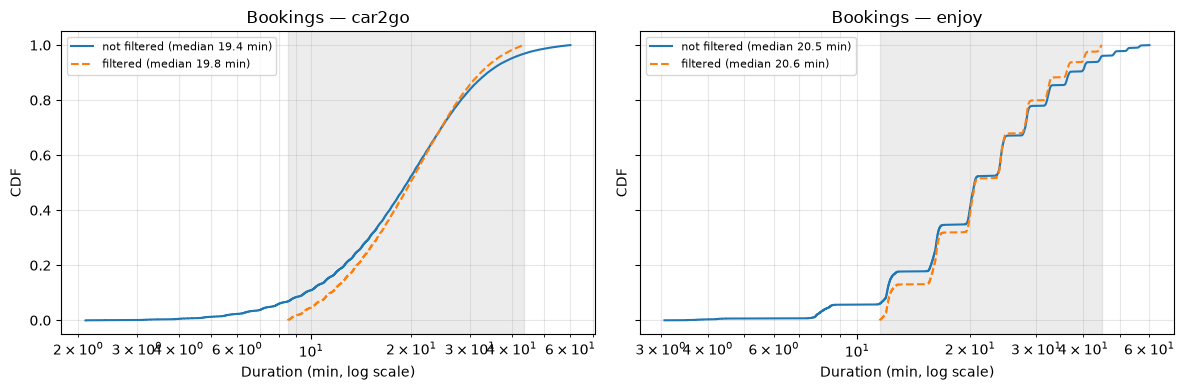

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ['car2go', 'enjoy']):
    plot_cdf_filtered(bookings[name], bookings_f[name], zones_f[name], f"Bookings — {name}", ax)
plt.tight_layout(); plt.show()

In [16]:
zones, ZONES = load_zones('data/IMQ/Zone/TorinoZonescol.geojson')
trips = {name: add_time_columns(assign_zones(df, zones)) for name, df in bookings_f.items()}

properties of the first zone: {'fill': '#555555', 'fill-opacity': 0.5}
108311/109502 bookings start and end inside the Torino zones (98.9%)
87093/87456 bookings start and end inside the Torino zones (99.6%)


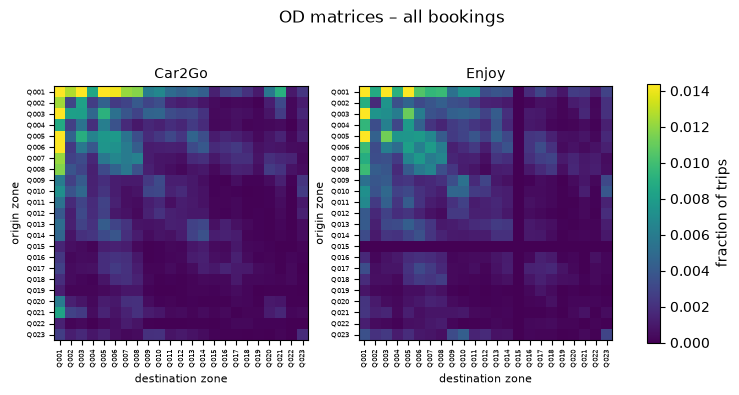

In [17]:
od_car2go = od_matrix(trips['car2go'], ZONES)
od_enjoy = od_matrix(trips['enjoy'], ZONES)
plot_heatmaps({'Car2Go': od_car2go, 'Enjoy': od_enjoy}, 'OD matrices – all bookings', 'task1_od')